# Figure S-LOCO consistency panels: per-cancer-type TSS rankings

Pan-cancer cohort (no_deep). Per-TSS differences from the healthy donors are computed per cancer type on
disjoint halves (healthy donors and each type halved in every random split), so two compared rankings
never share a sample. Agreement between types = between-type Spearman divided by the geometric mean of
the two within-type (split-half) Spearman values; 1 = as similar as two halves of one type.

- (a) per-TSS effect size *d* of the row-z-scored Griffin difference, 200 splits;
- (b) coefficients of the fixed pan-cancer LOCO configuration (elastic-net logistic regression, C = 10,
  l1_ratio 0.1) fitted on every half, 20 splits;
- (c) each type against the six other types pooled.

Lung has only 10 cancers (5 per half), so its values are the least certain.

Source data: `data/no_deep/figS_loco_consistency_{matrix,splits}.csv` and `_summary.json`, written by
`COHORT_VARIANT=no_deep python src/figures/export/export_figS_loco_consistency.py`. Run from `src/figures/`.

In [1]:
import os, json
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))
COHORT = os.environ.get("FIG_COHORT", "no_deep")
assert COHORT == "no_deep", "the LOCO analysis exists for the no_deep cohort only"
_DATA, _OUT = os.path.join("data", COHORT), os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

cons = pd.read_csv(os.path.join(_DATA, "figS_loco_consistency_matrix.csv"))
with open(os.path.join(_DATA, "figS_loco_consistency_summary.json")) as fh:
    summ = json.load(fh)
LABEL = {"Bile duct cancer": "Bile duct", "Breast cancer": "Breast", "Colorectal cancer": "Colorectal",
         "Gastric cancer": "Gastric", "Lung cancer naive nsclc": "Lung (NSCLC)", "Ovarian cancer": "Ovarian",
         "Pancreatic cancer": "Pancreatic"}
REST = "other types pooled"
STATS = [s for s in ["cohen_d", "weight"] if s in set(cons["statistic"])]
TYPES = sorted(set(cons["a"]) - {REST})
NTYPE = summ["n_per_type"]


def matrix(stat, col="disattenuated"):
    g = cons[(cons["statistic"] == stat) & (cons["b"] != REST)]
    M = pd.DataFrame(np.nan, index=TYPES, columns=TYPES)
    for _, r in g.iterrows():
        M.loc[r["a"], r["b"]] = M.loc[r["b"], r["a"]] = r[col]
    return M


# one type order for every panel: average-linkage clustering of the d matrix
_D = matrix("cohen_d").to_numpy().copy(); np.fill_diagonal(_D, 1.0)
ORDER = [TYPES[i] for i in leaves_list(linkage(squareform(1 - np.clip(_D, -1, 1), checks=False), "average"))]
print("statistics:", STATS, "| splits:", summ["n_splits"], "| order:", [LABEL[t] for t in ORDER])

statistics: ['cohen_d', 'weight'] | splits: {'cohen_d': 200, 'weight': 20} | order: ['Pancreatic', 'Gastric', 'Breast', 'Lung (NSCLC)', 'Colorectal', 'Bile duct', 'Ovarian']


In [2]:
def panel_matrix(ax, stat, title):
    M = matrix(stat).loc[ORDER, ORDER]
    W = matrix(stat, "rho_mean").loc[ORDER, ORDER]
    A = M.to_numpy().copy(); np.fill_diagonal(A, np.nan)
    im = ax.imshow(A, cmap="viridis", vmin=0, vmax=1)
    for i in range(len(ORDER)):
        for j in range(len(ORDER)):
            if i == j:
                ax.text(j, i, f"{W.iat[i, j]:.2f}", ha="center", va="center", fontsize=8.5, style="italic")
            else:
                ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center", fontsize=8.5, color="white" if A[i, j] < 0.6 else "black")
    lab = [f"{LABEL[t]} ({NTYPE[t]})" for t in ORDER]
    ax.set_xticks(range(len(lab))); ax.set_xticklabels(lab, rotation=45, ha="right", fontsize=9.5)
    ax.set_yticks(range(len(lab))); ax.set_yticklabels(lab, fontsize=9.5)
    ax.set_title(f"{title}\n({summ['n_splits'][stat]} splits; diagonal, italic: within-type Spearman)", loc="left", fontsize=10)
    return im


def panel_rest(ax):
    yy = np.arange(len(ORDER))
    cols = {"cohen_d": "#029E73", "weight": "#CC78BC"}
    for k, stat in enumerate(STATS):
        g = cons[(cons["statistic"] == stat) & (cons["b"] == REST)].set_index("a").loc[ORDER]
        ax.barh(yy + (k - (len(STATS) - 1) / 2) * 0.38, g["disattenuated"], height=0.36, color=cols[stat],
                label={"cohen_d": "per-TSS differences", "weight": "model coefficients"}[stat])
        for y_, v_ in zip(yy + (k - (len(STATS) - 1) / 2) * 0.38, g["disattenuated"]):
            ax.text(v_ + 0.015, y_, f"{v_:.2f}", va="center", ha="left", fontsize=8.5)
    ax.axvline(1, color="gray", lw=1, ls="--")
    ax.set_yticks(yy); ax.set_yticklabels([LABEL[t] for t in ORDER], fontsize=10); ax.invert_yaxis()
    ax.set_xlabel(r"$\frac{\mathrm{Spearman\ with\ the\ six\ other\ types\ pooled}}{\sqrt{\mathrm{within\ type}\ \times\ \mathrm{within\ pooled}}}$" + "\n(1 = as similar as two halves of the type itself)", fontsize=11)
    ax.set_xlim(0, 1.15); ax.grid(axis="x", alpha=0.3)
    ax.legend(fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 1.01), ncol=2, frameon=False)

## Assembled panels

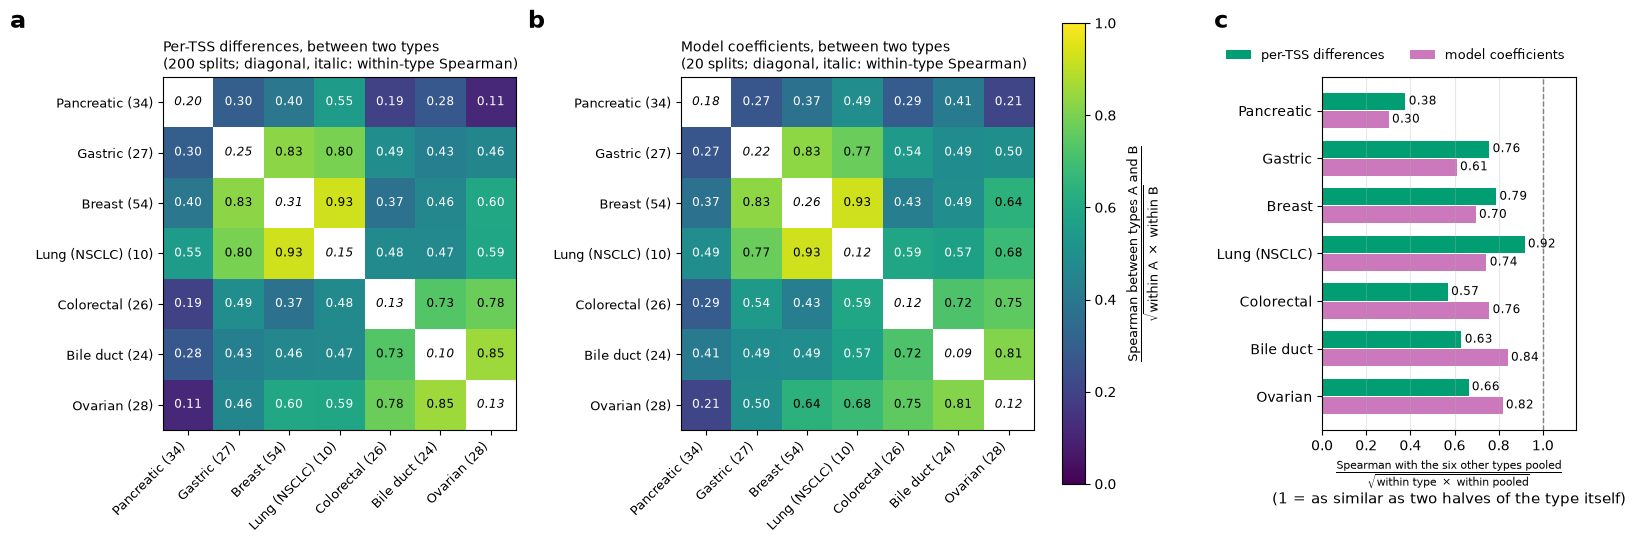

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6.2), gridspec_kw={"width_ratios": [1, 1, 0.8], "wspace": 0.5})
im = panel_matrix(axes[0], "cohen_d", "Per-TSS differences, between two types")
if "weight" in STATS:
    panel_matrix(axes[1], "weight", "Model coefficients, between two types")
else:
    axes[1].text(0.5, 0.5, "coefficient version not computed yet", ha="center", va="center", transform=axes[1].transAxes); axes[1].axis("off")
cb = fig.colorbar(im, ax=axes[:2], fraction=0.025, pad=0.03)
cb.set_label(r"$\frac{\mathrm{Spearman\ between\ types\ A\ and\ B}}{\sqrt{\mathrm{within\ A}\ \times\ \mathrm{within\ B}}}$", fontsize=13, labelpad=8)
panel_rest(axes[2])
# panel c to the height of the square matrix panels, letters on one line
fig.canvas.draw()
pa = axes[0].get_position(); pc = axes[2].get_position()
axes[2].set_position([pc.x0 + 0.035, pa.y0, pc.width - 0.035 + 0.01, pa.height])
for ax, letter, dx in zip(axes, "abc", (0.085, 0.085, 0.06)):
    fig.text(ax.get_position().x0 - dx, pa.y1 + 0.07, letter, fontsize=17, fontweight="bold", va="bottom")
fig.savefig(os.path.join(_OUT, "figS_loco_consistency.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(_OUT, "figS_loco_consistency.pdf"), bbox_inches="tight")
plt.show()

## Summary numbers

In [4]:
pd.set_option("display.width", 200)
for stat in STATS:
    s = summ[stat]
    print(f"{stat}: within-type split-half Spearman " + ", ".join(f"{LABEL[t]} {v:.3f}" for t, v in s["within"].items()))
    print(f"  between types: median Spearman {s['between_median']:.3f}, median corrected agreement {s['disattenuated_median']:.2f}")
    print("  vs the six other types pooled: " + ", ".join(f"{LABEL[t]} {v:.2f}" for t, v in s["vs_rest_disattenuated"].items()))
print()
print(cons.drop(columns=["rho_sd"]).round(3).to_string(index=False))

cohen_d: within-type split-half Spearman Bile duct 0.104, Breast 0.308, Colorectal 0.133, Gastric 0.251, Lung (NSCLC) 0.147, Ovarian 0.131, Pancreatic 0.198
  between types: median Spearman 0.084, median corrected agreement 0.48
  vs the six other types pooled: Bile duct 0.63, Breast 0.79, Colorectal 0.57, Gastric 0.76, Lung (NSCLC) 0.92, Ovarian 0.66, Pancreatic 0.38
weight: within-type split-half Spearman Bile duct 0.088, Breast 0.258, Colorectal 0.122, Gastric 0.221, Lung (NSCLC) 0.120, Ovarian 0.118, Pancreatic 0.177
  between types: median Spearman 0.076, median corrected agreement 0.54
  vs the six other types pooled: Bile duct 0.84, Breast 0.70, Colorectal 0.76, Gastric 0.61, Lung (NSCLC) 0.74, Ovarian 0.82, Pancreatic 0.30

statistic                       a                       b  rho_mean  rho_lo  rho_hi  disattenuated  within_a  within_b
  cohen_d        Bile duct cancer        Bile duct cancer     0.104   0.087   0.118          1.000     0.104     0.104
  cohen_d        Bil